# Projeto: Análise de Custos de Clientes de um Plano de Saúde
### PjBL 1: Machine Learning

**Integrantes do grupo:**
- Caliel Carvalho de Medeiros
- Enzo Erkmann
- Felipe Coelho Ramos
- Leonardo Soares de Mattos

A proposta é analisar a base de clientes da operadora em três partes. Primeiro, estimar o valor da cobrança de cada cliente. Depois, classificar quais clientes podem ser considerados de alto custo. Por fim, separar a base em grupos com perfis parecidos para apoiar ações comerciais.

Para isso, usamos regressão linear, regressão logística e K-Means. Em cada etapa avaliamos o resultado com métricas e gráficos adequados.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    r2_score, mean_squared_error,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Usamos a mesma semente nos passos aleatórios para conseguir reproduzir os resultados
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams["figure.figsize"] = (7, 4.5)


## 1. Carregando os dados

A base fornecida tem 100 clientes. As variáveis disponíveis são idade, IMC, número de filhos, se o cliente é fumante e o valor da cobrança.


In [ ]:
data = {
    "idade":   [58, 24, 19, 63, 18, 31, 40, 42, 30, 23,
                41, 61, 28, 32, 20, 63, 34, 45, 23, 61,
                53, 52, 28, 50, 58, 51, 41, 54, 52, 34,
                62, 46, 19, 58, 50, 54, 24, 64, 64, 46,
                53, 23, 31, 42, 64, 36, 38, 50, 33, 20,
                34, 60, 57, 34, 36, 59, 26, 36, 34, 58,
                34, 25, 41, 20, 53, 33, 65, 65, 20, 37,
                43, 59, 19, 24, 50, 45, 65, 57, 37, 30,
                37, 55, 50, 23, 33, 33, 58, 27, 45, 53,
                53, 64, 28, 58, 46, 52, 31, 31, 54, 44],
    "imc":     [36.1, 22.9, 32.1, 24.1, 28.7, 33.7, 19.8, 32.9, 28.0, 35.9,
                31.4, 23.6, 23.9, 23.9, 30.6, 25.0, 34.8, 33.4, 28.9, 26.6,
                29.1, 28.6, 16.0, 29.0, 24.5, 35.6, 36.7, 30.9, 28.8, 20.4,
                30.1, 33.8, 24.8, 30.6, 29.2, 24.5, 33.7, 36.7, 22.1, 30.9,
                35.6, 38.9, 37.0, 27.5, 36.1, 28.9, 35.9, 31.9, 16.7, 23.9,
                31.2, 24.5, 48.5, 32.2, 34.7, 19.7, 27.4, 21.0, 23.9, 24.2,
                31.9, 39.6, 25.5, 31.8, 33.1, 39.3, 37.8, 30.3, 31.2, 33.7,
                22.8, 19.5, 40.4, 24.0, 38.1, 42.2, 28.2, 23.9, 25.8, 16.0,
                19.1, 24.4, 16.0, 26.6, 26.5, 36.7, 20.0, 28.1, 30.6, 28.6,
                16.4, 33.4, 28.2, 26.7, 32.9, 31.5, 34.1, 31.5, 28.0, 19.0],
    "filhos":  [0, 0, 2, 0, 1, 0, 2, 2, 0, 1,
                2, 0, 4, 3, 0, 1, 1, 0, 0, 1,
                2, 1, 3, 0, 1, 1, 1, 1, 1, 5,
                5, 0, 0, 0, 0, 1, 1, 2, 0, 1,
                1, 0, 0, 1, 2, 2, 1, 2, 2, 2,
                0, 4, 0, 0, 2, 2, 2, 0, 4, 0,
                2, 4, 0, 0, 2, 3, 1, 3, 3, 0,
                5, 3, 0, 3, 0, 1, 1, 2, 2, 2,
                1, 1, 3, 2, 0, 3, 1, 3, 2, 1,
                4, 4, 0, 1, 0, 1, 1, 3, 1, 3],
    "fumante": [0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
                0, 0, 0, 0, 1, 1, 0, 1, 0, 1,
                0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
                0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
                0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
                0, 1, 0, 0, 0, 1, 0, 0, 0, 1,
                0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
                0, 0, 1, 0, 0, 0, 1, 0, 0, 1,
                0, 0, 0, 0, 0, 0, 0, 1, 0, 1,
                0, 0, 0, 0, 0, 0, 0, 1, 1, 1],
    "cobranca": [ 8153.31,  2281.46,  4869.30,  6174.27,  3490.86,
                  4809.50,  4607.64, 19643.72,  4344.88,  3527.45,
                  6903.47,  5916.90,  5523.08,  3983.00, 17711.26,
                 22083.53,  6625.06, 19696.49,  2485.47, 21645.09,
                  6992.70,  5307.29,  5168.77,  5290.30,  6884.36,
                  6486.07,  5239.39,  6863.23,  6270.68, 21797.07,
                  9425.17,  5690.94,  3203.20,  7084.05,  7438.21,
                  6314.95,  5228.05,  8810.81,  8293.24, 17329.94,
                  7846.94,  3980.08,  3902.83,  7204.32,  8356.69,
                  5986.04, 17625.99,  7261.44,  5825.85,  3565.46,
                  6309.61, 17344.01,  7944.13,  5700.12,  7329.92,
                 17615.89,  6496.94,  3861.33,  5833.33, 21986.35,
                  6468.00,  6830.78,  5085.56,  3682.07,  6782.37,
                 14951.86,  7629.70,  7833.09,  4431.57,  4018.46,
                  8217.61,  7218.72, 17974.87,  4339.84,  7925.31,
                  6951.38, 24529.93,  8523.35,  4991.86, 20294.65,
                  5749.30,  6225.73,  6648.61,  5690.78,  4225.16,
                  6131.19,  6057.06, 16028.61,  7952.93, 23650.37,
                  5818.59,  8294.36,  3524.99,  8408.93,  6461.03,
                  7071.84,  5647.48, 15236.89, 23686.99, 19655.90]
}

df = pd.DataFrame(data)
df.head()


,idade,imc,filhos,fumante,cobranca
0,58,36.1,0,0,8153.31
1,24,22.9,0,0,2281.46
2,19,32.1,2,0,4869.30
3,63,24.1,0,0,6174.27
4,18,28.7,1,0,3490.86


## 2. Análise exploratória

Antes dos modelos, vamos olhar a distribuição dos dados e principalmente como fumante e idade se relacionam com cobranca.


In [ ]:
df.describe()


,idade,imc,filhos,fumante,cobranca
count,100.000000,100.000000,100.000000,100.000000,100.000000
mean,42.370000,29.054000,1.450000,0.200000,8724.191500
std,14.230182,6.407058,1.351206,0.402015,5751.639661
min,18.000000,16.000000,0.000000,0.000000,2281.460000
25%,31.000000,24.350000,0.000000,0.000000,5277.572500
50%,42.000000,28.950000,1.000000,0.000000,6636.835000
75%,54.000000,33.475000,2.000000,0.000000,8309.942500
max,65.000000,48.500000,5.000000,1.000000,24529.930000


In [ ]:
# A cobrança tem assimetria à direita. Existem poucos clientes com valores bem maiores
# que o restante da base, o que já indica a presença de um grupo de custo mais alto.
print(f"Assimetria (skew) de 'cobranca': {df['cobranca'].skew():.2f}")


Assimetria (skew) de 'cobranca': 1.46


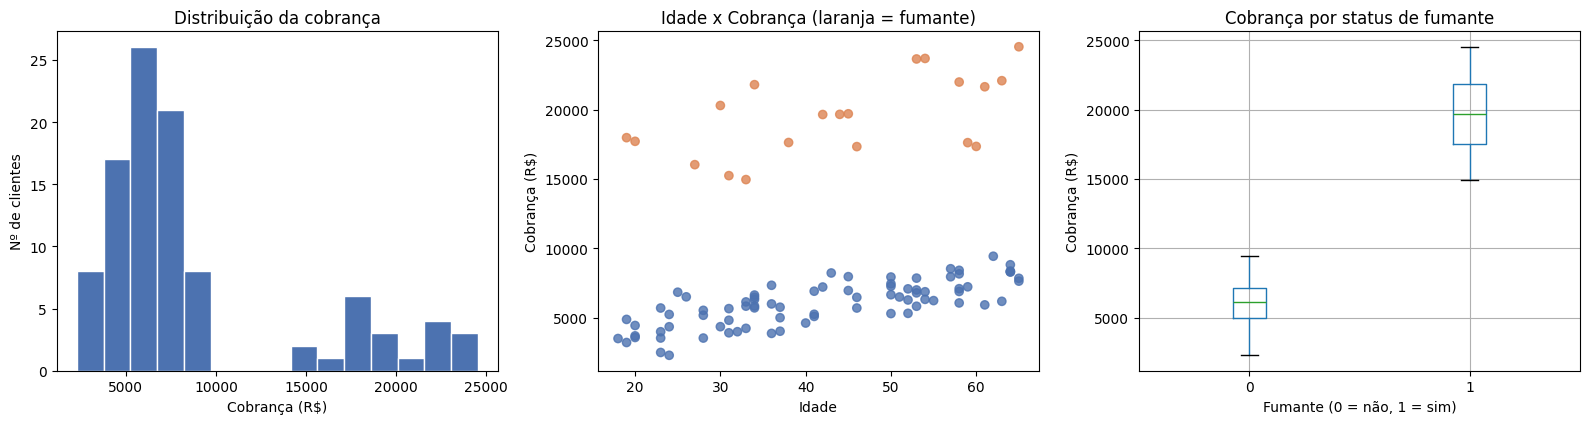

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].hist(df["cobranca"], bins=15, color="#4C72B0", edgecolor="white")
axes[0].set_title("Distribuição da cobrança")
axes[0].set_xlabel("Cobrança (R$)")
axes[0].set_ylabel("Nº de clientes")

cores = df["fumante"].map({0: "#4C72B0", 1: "#DD8452"})
axes[1].scatter(df["idade"], df["cobranca"], c=cores, alpha=0.8)
axes[1].set_title("Idade x Cobrança (laranja = fumante)")
axes[1].set_xlabel("Idade")
axes[1].set_ylabel("Cobrança (R$)")

df.boxplot(column="cobranca", by="fumante", ax=axes[2])
axes[2].set_title("Cobrança por status de fumante")
axes[2].set_xlabel("Fumante (0 = não, 1 = sim)")
axes[2].set_ylabel("Cobrança (R$)")
plt.suptitle("")

plt.tight_layout()
plt.show()


**Leitura da análise exploratória:** o boxplot mostra uma diferença bem clara entre fumantes e não fumantes. No gráfico de idade por cobrança também dá para perceber que os fumantes ficam em uma faixa de custo muito mais alta. A idade parece aumentar a cobrança, mas o efeito de ser fumante é bem mais forte. A regressão linear vai ajudar a medir isso pelos coeficientes.


## 3. Regressão Linear: previsão do valor da cobrança

Usamos idade, imc, filhos e fumante para prever cobranca com regressão linear múltipla. A base foi separada em 80% para treino e 20% para teste, com random_state fixo.

Para avaliar o modelo usamos R² e RMSE. O R², também conhecido como Coeficiente de Determinação, é uma medida estatística que indica o quanto a variação de uma variável dependente (o que está tentando prever) é explicada pelas variáveis independentes (os dados que estão sendo usados para fazer a previsão) em um modelo de regressão. Geralmente, quanto maior o R², melhor o modelo se ajusta aos dados.

Já o RMSE (Raiz do Erro Quadrático Médio) mede o tamanho típico dos erros de previsão na mesma unidade da cobrança e dá mais peso para erros maiores. Quanto menor for o RMSE, melhor (significa que o erro é menor). Um RMSE = 0 indicaria um modelo perfeito (os pontos reais estariam todos exatamente sobre a linha de regressão).


In [ ]:
features = ["idade", "imc", "filhos", "fumante"]
X = df[features]
y = df["cobranca"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

modelo_linear = LinearRegression()
modelo_linear.fit(X_train, y_train)
pred_linear = modelo_linear.predict(X_test)

r2 = r2_score(y_test, pred_linear)
rmse = mean_squared_error(y_test, pred_linear) ** 0.5

print(f"R²   = {r2:.3f}")
print(f"RMSE = R$ {rmse:,.2f}")


R²   = 0.930
RMSE = R$ 1,280.87


O R² ficou próximo de 0,93, significando um valor bem alto para problemas reais. Isso significa que o modelo explica cerca de 93% da variação da cobrança no conjunto de teste a partir das quatro características fornecidas (idade, imc, filhos e fumantes). Apresenta que apenas 7% do valor da cobrança acaba dependendo de fatores desconhecidos pelo modelo, como por exemplo, histórico familiar de doenças, tipo do plano, região onde a pessoa mora ou ocorrência de flutuações aleatórias. Foi obtido um excelente resultado de R².

O RMSE ficou em aproximadamente 1.280 reais. Esse valor representa a magnitude típica dos erros de previsão, com maior penalização para erros grandes. Comparando com a cobrança média da base, que fica perto de 8.724 reais, o erro ficou relativamente baixo. Além disso, o menor valor de cobrança da lista é de 2.281 reais, enquanto o maior chega a mais de 24.529 reais. Como os valores variam em uma escala maior de 20 mil reais, o erro encontrado pelo RMSE é consideravelmente baixo. O modelo consegue muito bem identificar quem vai pagar os valores mais baixos e quem os mais altos.

In [ ]:
# Ordenamos os coeficientes pela magnitude para ver quais variáveis mais alteram a cobrança
coeficientes = pd.Series(modelo_linear.coef_, index=features).sort_values(
    key=abs, ascending=False
)
print("Intercepto:", f"R$ {modelo_linear.intercept_:,.2f}")
print("\nCoeficientes:")
print(coeficientes.round(2))


Intercepto: R$ 1,111.85

Coeficientes:
fumante    13349.27
filhos       124.97
idade         87.99
imc           32.71
dtype: float64


**Interpretação dos coeficientes:** fumante é a variável que mais pesa no modelo. O coeficiente ficou em aproximadamente R\$ 13.349. Mantendo as outras variáveis constantes, um cliente fumante tem uma cobrança prevista cerca de R\$ 13,3 mil maior que um não fumante.

A cobrança total de acordo com o cálculo dos coeficientes e do intercepto fica de acordo com a fórmula abaixo.

`Cobrança = Intercepto + (Idade x 87.99) + (IMC x 32.71) + (Filhos x 124.97) + (Fumante x 13349.27)`

O valor do intercepto representa o ponto de partida do modelo, representando o valor da cobrança se todas as variáveis do cliente fossem zero (0 anos, 0 de IMC, 0 filhos, não fumante). Representa uma "taxa fixa" inicial antes de começar a somar os riscos do cliente.

Como é possível validar, os outros coeficientes são bem menores. O efeito do IMC fica em torno de R\$ 33 por unidade e o de cada filho adicional em torno de R\$ 125. A idade também aumenta a cobrança, mas de forma bem mais gradual.

Então, nessa base, o principal fator associado ao aumento da cobrança é o cliente ser fumante. Isso é consistente com o que apareceu nos gráficos da análise exploratória realizados no item 2 do trabalho. Além disso, se considerar em termos de negócio para uma seguradora de saúde, o resultado faz total sentido, já que o tabagismo aumenta exponencialmente o risco de doenças crônicas graves. Portanto, o modelo aprendeu que o risco (e o custo futuro) de segurar um paciente fumante é muito mais alto.


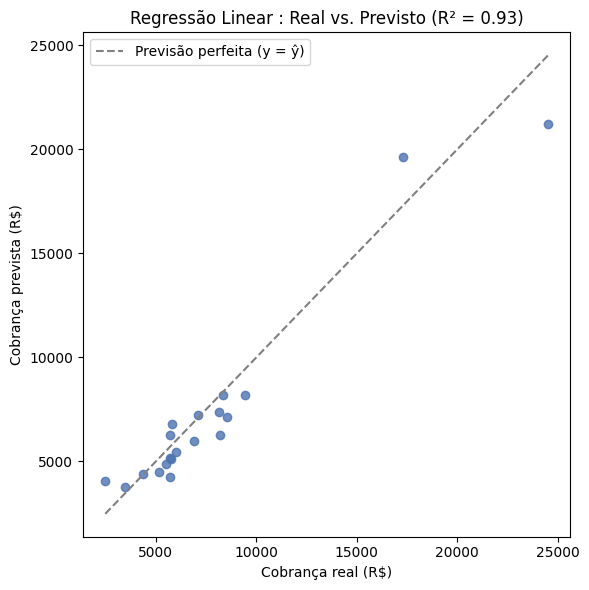

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_linear, alpha=0.8, color="#4C72B0")
lims = [min(y_test.min(), pred_linear.min()), max(y_test.max(), pred_linear.max())]
plt.plot(lims, lims, "--", color="gray", label="Previsão perfeita (y = ŷ)")
plt.xlabel("Cobrança real (R$)")
plt.ylabel("Cobrança prevista (R$)")
plt.title(f"Regressão Linear : Real vs. Previsto (R² = {r2:.2f})")
plt.legend()
plt.tight_layout()
plt.show()


**Análise da Visualização (Real vs. Previsto)**

O gráfico de dispersão mostra visualmente a alta precisão do modelo de regressão linear desenvolvido e confirma o R² obtido. É possível ver que muitos dos pontos azuis (que mostram os valores predizidos frente aos reais de teste) estão bem alinhados e agrupados ao longo da linha tracejada cinza, que mostra a previsão perfeita. Também justifica o alto valor de R² (0.93), já que o forte alinhamento diagonal fez com que o modelo conseguisse estimar valores bem próximos da cobrança real.

Além disso, não é possível ver uma dispersão em formato de "cone" ou nuvem aleatória, indicando que o modelo mantém um bom padrão de acerto tanto para as cobranças mais baixas quanto para as mais altas. Os poucos pontos que se distanciam ligeiramente da reta principal representam os resíduos do modelo, ilustrando de forma prática a margem de erro capturada pelo RMSE.

## 4. Regressão Logística: classificação de clientes de alto custo

Para criar a classe de alto custo, usamos o terceiro quartil da cobrança, ou percentil 75, como limiar. Assim, os 25% de clientes com maiores cobranças ficam na classe de alto custo.

A escolha faz sentido por dois motivos. Primeiro, a distribuição da cobrança é assimétrica à direita e existe um grupo menor de clientes com valores bem altos. Segundo, para a operadora é mais útil concentrar a análise em uma parte menor da carteira do que marcar metade dos clientes como alto custo.

Com isso, o limiar não é um valor escolhido aleatoriamente. Ele vem da própria distribuição dos dados e ainda gera uma quantidade de casos que faz sentido para uma análise de risco.


In [ ]:
limiar = df["cobranca"].quantile(0.75)
df["alto_custo"] = (df["cobranca"] >= limiar).astype(int)

print(f"Limiar (percentil 75): R$ {limiar:,.2f}")
print(df["alto_custo"].value_counts().rename({0: "custo normal", 1: "alto custo"}))


Limiar (percentil 75): R$ 8,309.94
alto_custo
custo normal    75
alto custo      25
Name: count, dtype: int64


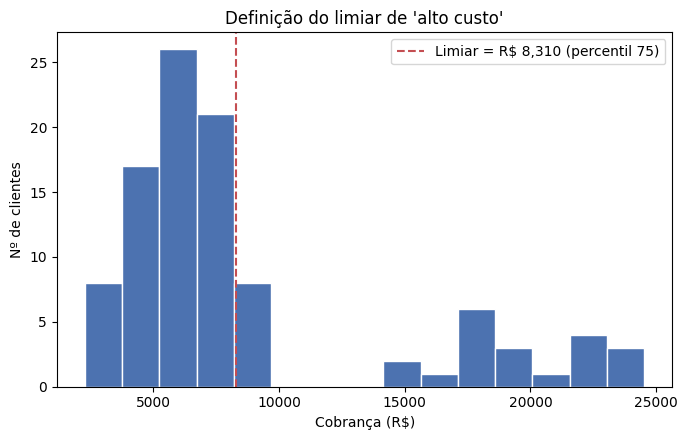

In [ ]:
plt.figure()
plt.hist(df["cobranca"], bins=15, color="#4C72B0", edgecolor="white")
plt.axvline(limiar, color="#C44E52", linestyle="--",
            label=f"Limiar = R$ {limiar:,.0f} (percentil 75)")
plt.xlabel("Cobrança (R$)")
plt.ylabel("Nº de clientes")
plt.title("Definição do limiar de 'alto custo'")
plt.legend()
plt.tight_layout()
plt.show()


**Treinamento:** usamos novamente idade, imc, filhos e fumante como entradas. A variável cobranca não entra no modelo porque a classe alto_custo foi criada diretamente a partir dela. Usar cobranca como entrada faria o modelo receber praticamente a resposta pronta, o que seria vazamento de dados.

Como temos 75% dos clientes na classe normal e 25% na classe de alto custo, usamos stratify na divisão entre treino e teste para manter essa proporção nos dois conjuntos.


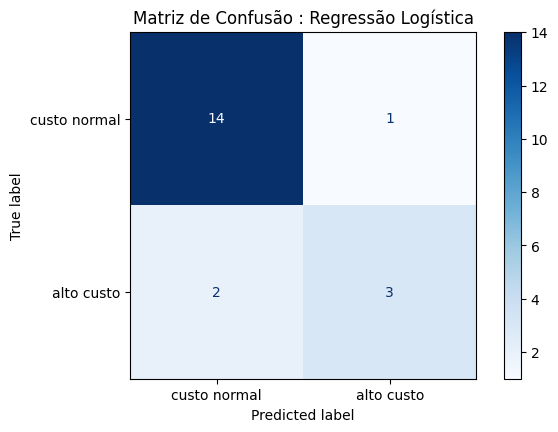

              precision    recall  f1-score   support

custo normal       0.88      0.93      0.90        15
  alto custo       0.75      0.60      0.67         5

    accuracy                           0.85        20
   macro avg       0.81      0.77      0.78        20
weighted avg       0.84      0.85      0.84        20



In [ ]:
X2 = df[features]
y2 = df["alto_custo"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=RANDOM_STATE, stratify=y2
)

modelo_logistico = LogisticRegression()
modelo_logistico.fit(X2_train, y2_train)
pred_logistico = modelo_logistico.predict(X2_test)

cm = confusion_matrix(y2_test, pred_logistico)
disp = ConfusionMatrixDisplay(cm, display_labels=["custo normal", "alto custo"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de Confusão : Regressão Logística")
plt.show()

print(classification_report(y2_test, pred_logistico,
                             target_names=["custo normal", "alto custo"]))


**Interpretação dos resultados:** no conjunto de teste, o modelo acertou a classificação de 17 dos 20 clientes, chegando a uma acurácia de 85%. Olhando a matriz de confusão com mais atenção, vemos que ele classificou corretamente 14 dos 15 clientes de custo normal. Entre os 5 clientes de alto custo, acertou 3 e deixou 2 sem identificar. Além disso, apenas 1 cliente de custo normal foi classificado incorretamente como alto custo.

Na classe de alto custo, a precisão foi de 0,75. Isso quer dizer que, dos 4 clientes apontados pelo modelo como sendo de alto custo, 3 realmente pertenciam a essa classe. O recall foi de 0,60, pois o modelo encontrou 3 dos 5 clientes de alto custo presentes no teste. O F1-score ficou em 0,67 e resume esse equilíbrio entre precisão e recall. Esses resultados também mostram que o modelo teve mais facilidade para reconhecer os clientes de custo normal, classe em que o recall chegou a 0,93.

Mesmo com uma acurácia de 85%, não podemos avaliar o modelo somente por esse número. A base é desbalanceada, já que 75% dos clientes estão na classe de custo normal. Se um modelo classificasse todos os clientes como normais, ele já teria 75% de acurácia, mas seria inútil para encontrar os casos de alto custo. A regressão logística ficou 10 pontos percentuais acima dessa referência e conseguiu encontrar parte dos casos mais importantes. Ainda assim, deixou passar 40% dos clientes de alto custo do teste, o que é uma limitação relevante.

Para a operadora, deixar de identificar um cliente que realmente possui alto custo pode ser mais prejudicial do que analisar por engano um cliente de custo normal. Por isso, em uma aplicação voltada à triagem de clientes, faria sentido dar mais importância ao recall. Uma forma de tentar aumentá-lo seria diminuir o limiar de decisão do modelo, que por padrão é de 0,50. Isso provavelmente faria o modelo encontrar mais clientes de alto custo, mas também aumentaria a quantidade de falsos positivos. A escolha desse limiar precisaria considerar o custo de cada tipo de erro para a operadora, além da relação entre precisão e recall.

Também é importante lembrar que o conjunto de teste possui somente 20 clientes, sendo apenas 5 deles de alto custo. Nesse cenário, um único acerto ou erro já altera o recall dessa classe em 20 pontos percentuais. Portanto, as métricas podem variar bastante com uma divisão diferente dos dados. Uma base maior e novas avaliações, usando validação cruzada estratificada, ajudariam a verificar se o desempenho se mantém.

Por fim, a expressão "alto custo" tem um significado específico neste trabalho: ela representa os 25% maiores valores de cobrança da amostra, com limiar de R$ 8.309,94. Esse valor não deve ser entendido como um limite válido para qualquer plano de saúde. De forma geral, o resultado indica que idade, IMC, número de filhos e condição de fumante ajudam o modelo a reconhecer parte dos clientes com maiores cobranças. Porém, como a base é pequena, a conclusão ainda deve ser considerada inicial. Para usar o modelo em uma situação real, seria necessário definir o que a operadora considera alto custo e fazer uma nova validação com uma base maior e mais representativa.


## 5. K-Means: segmentação dos clientes

O objetivo desta etapa é aplicar o algoritmo K-Means para identificar e agrupar os clientes em perfis semelhantes. Mas, antes de iniciar o treinamento do modelo, é preciso aplicar a normalização dos dados. As variáveis que utilizaremos misturam grandezas muito diferentes: a Cobrança opera na casa dos milhares de reais, enquanto a condição de Fumante é binária (0 ou 1), e a Idade e o IMC variam na casa das dezenas.

Como o funcionamento do K-Means baseia-se no cálculo da distância matemática entre os pontos, inserir os dados crus seria um problema. A variável de Cobrança teria um peso desproporcional na formação dos clusters e acabaria ofuscando a importância dos outros atributos dos pacientes. Para corrigir essa distorção e garantir que todas as características tenham a mesma relevância na decisão do modelo, aplicamos o StandardScaler, que coloca todas as variáveis em uma escala comparável.

In [ ]:
cluster_features = ["idade", "imc", "filhos", "fumante", "cobranca"]
Xc = df[cluster_features]

# Aplicação da normalização. Sem ela, a cobrança dominaria as distâncias por estar em uma escala muito maior.
scaler = StandardScaler()
Xc_scaled = scaler.fit_transform(Xc)
Xc_scaled[:5].round(2)


array([[ 1.1 ,  1.11, -1.08, -0.5 , -0.1 ],
       [-1.3 , -0.97, -1.08, -0.5 , -1.13],
       [-1.65,  0.48,  0.41, -0.5 , -0.67],
       [ 1.46, -0.78, -1.08, -0.5 , -0.45],
       [-1.72, -0.06, -0.33, -0.5 , -0.91]])

### Método do cotovelo: escolha do número de grupos

O algoritmo K-Means exige que o número de grupos, representado pela variável k, seja definido previamente. Porém, como não há uma resposta certa sobre quantos perfis distintos existem nesta base de dados, utilizamos o Método do Cotovelo para encontrar o valor mais adequado.

Para isso, treinamos o modelo repetidas vezes testando valores de k de 1 a 10, e calculamos a 'inércia' para cada tentativa. A inércia é uma métrica que avalia a coesão interna dos agrupamentos: quanto menor ela for, mais próximos e semelhantes são os dados dentro de um mesmo grupo.

A lógica do método consiste em plotar esses valores em um gráfico de linha e procurar pelo ponto de inflexão, que remete visualmente a um cotovelo. Esse ponto indica o número ideal de clusters, pois é o momento em que a criação de novos grupos deixa de trazer grandes reduções na inércia, o que nos garante um modelo mais balanceado e interpretável.

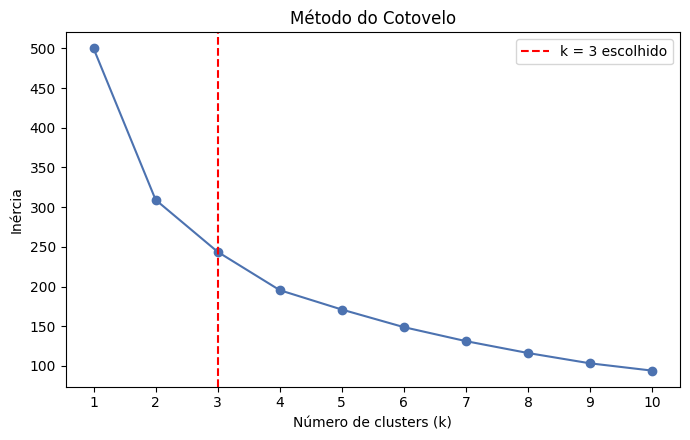

k=1: inércia=500.0
k=2: inércia=309.2
k=3: inércia=243.7
k=4: inércia=195.5
k=5: inércia=171.0
k=6: inércia=148.9
k=7: inércia=131.2
k=8: inércia=116.3
k=9: inércia=103.3
k=10: inércia=94.1


In [ ]:
inercias = []
# Testamos uma faixa de 1 a 10 clusters para identificar onde a redução do erro ocorre
ks = range(1, 11)

for k in ks:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(Xc_scaled)
    # A métrica inertia_ extrai o cálculo do WCSS nativo do scikit-learn
    inercias.append(km.inertia_)

plt.figure()
plt.plot(list(ks), inercias, marker="o", color="#4C72B0")
# A linha de marcação justifica visualmente a escolha do k=3
plt.axvline(3, color="red", linestyle="--", label="k = 3 escolhido")

plt.xlabel("Número de clusters (k)")
plt.ylabel("Inércia")
plt.title("Método do Cotovelo")
plt.xticks(list(ks))
plt.legend()
plt.tight_layout()
plt.show()

# Impressão dos valores absolutos para facilitar a documentação e análise do relatório
for k, inercia in zip(ks, inercias):
    print(f"k={k}: inércia={inercia:.1f}")


Ao analisar a curva de redução da inércia, observamos que a queda mais brusca ocorre de k=1 para k=2, no entanto, a transição para k=3 ainda apresenta uma redução significativa (queda de 65,5 pontos). A partir de k=3, as reduções tornam-se marginais, o que indica que adicionar novos agrupamentos não traria ganhos relevantes.

Tentamos utilizar 4 clusters durante os testes, mas a compreensão entre variáveis e agrupamentos tornou-se mais complexa, e o ganho de informações não compensou a perda de simplicidade na visualização. O ponto k=3 forma o verdadeiro 'cotovelo' da curva, pois marca o equilíbrio mais adequado entre o rigor matemático e uma segmentação de mercado útil e interpretável para a operadora.

In [ ]:
# Instanciamos o modelo final com k=3
# n_init=10 garante que o algoritmo teste 10 posições iniciais diferentes para os centróides, evitando mínimos locais
kmeans_final = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
df["cluster"] = kmeans_final.fit_predict(Xc_scaled)

# Agrupamos os dados pela nova coluna de cluster e calculamos a média das características não normalizadas, para facilitar a interpretação
perfil_clusters = df.groupby("cluster")[cluster_features].mean().round(2)
perfil_clusters["n_clientes"] = df["cluster"].value_counts().sort_index()
perfil_clusters


,idade,imc,filhos,fumante,cobranca,n_clientes
cluster,,,,,,
0,55.00,30.08,1.32,0.0,7101.26,38
1,44.10,28.16,1.70,1.0,19524.47,20
2,30.12,28.55,1.45,0.0,5049.56,42


**Interpretação dos clusters:**

- Cluster 0 (Clientes senhores de custo moderado): Com idade média próxima a 55 anos, este grupo não possui fumantes e apresenta uma cobrança média em torno de R$ 7.100. A idade avançada é o fator determinante que eleva o custo de assistência em relação aos clientes mais jovens.

- Cluster 1 (Fumantes de alto custo): Formado por clientes com idade média de 44 anos, este grupo se destaca por ter 100% de fumantes e a maior cobrança da base, na faixa de R$ 19.500. Representa o perfil de maior risco financeiro. Esse grupo valida os resultados da regressão linear, isolando o tabagismo como a variável de maior impacto no encarecimento do plano de saúde.

- Cluster 2 (Clientes jovens de baixo custo): Concentra o público na faixa dos 30 anos, sem fumantes, e possui a menor cobrança média com R$ 5.050. Representam a fatia de menor risco e melhor custo/benefício para a operadora.

Para a equipe comercial e de gestão da operadora, essa divisão fornece uma boa visão estratégica, pois permite que tratem os diferentes perfis de maneiras que se adequem a cada um deles. O Cluster 1 exige maior atenção devido a seu custo elevado para a empresa, necessitando melhores políticas de mitigação de risco e um repasse adequado dos custos. O Cluster 2 compõe o cenário ideal para planos de entrada e campanhas de fidelização de longo prazo. Já o Cluster 0 demanda um acompanhamento estruturado, com ofertas de serviços voltados à terceira idade e medicina preventiva para evitar que os custos aumentem no futuro.

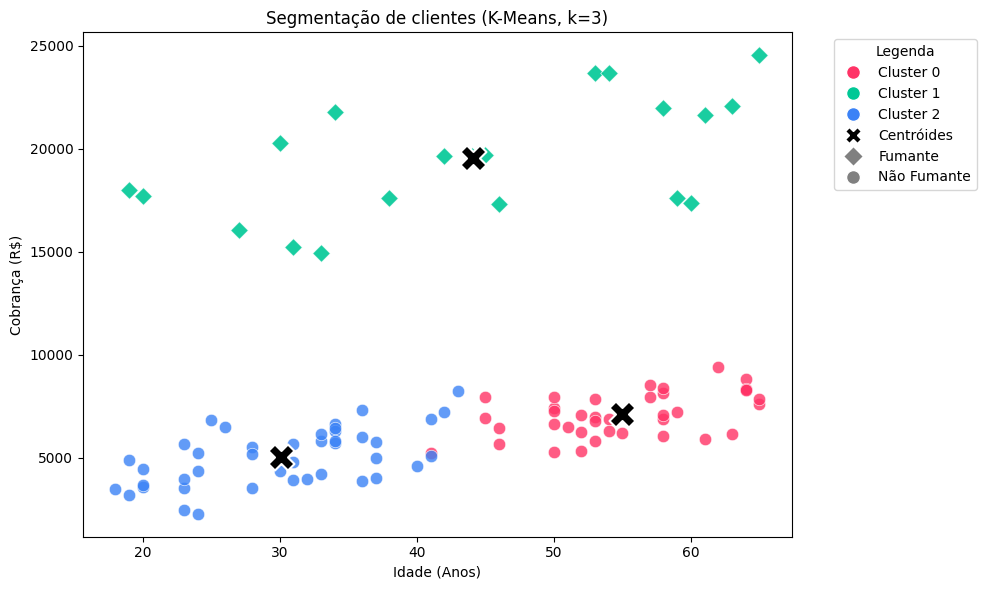

In [ ]:
cores_cluster = ["#FF3366", "#00C896", "#3B82F6"]
plt.figure(figsize=(10, 6))

# Iteramos sobre os clusters para plotar os dados
for c in sorted(df["cluster"].unique()):
    subset = df[df["cluster"] == c]

    fumantes = subset[subset["fumante"] == 1]
    nao_fumantes = subset[subset["fumante"] == 0]

    # Não Fumantes
    if not nao_fumantes.empty:
        plt.scatter(nao_fumantes["idade"], nao_fumantes["cobranca"],
                    color=cores_cluster[c], marker="o", s=80,
                    edgecolor="white", linewidth=0.5, alpha=0.8)

    # Fumantes
    if not fumantes.empty:
        plt.scatter(fumantes["idade"], fumantes["cobranca"],
                    color=cores_cluster[c], marker="D", s=80,
                    edgecolor="white", linewidth=0.5, alpha=0.9)

# Centróides
centroides_reais = scaler.inverse_transform(kmeans_final.cluster_centers_)
plt.scatter(centroides_reais[:, 0], centroides_reais[:, 4],
            marker='X', s=350, color='black', edgecolor='white',
            linewidth=1.5, zorder=5)

plt.xlabel("Idade (Anos)")
plt.ylabel("Cobrança (R$)")
plt.title("Segmentação de clientes (K-Means, k=3)")

# Legenda
elementos_legenda = [
    # Clusters
    Line2D([0], [0], marker='o', color='w', label='Cluster 0', markerfacecolor=cores_cluster[0], markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Cluster 1', markerfacecolor=cores_cluster[1], markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Cluster 2', markerfacecolor=cores_cluster[2], markersize=10),
    # Centróide
    Line2D([0], [0], marker='X', color='w', label='Centróides', markerfacecolor='black', markeredgecolor='white', markersize=12),
    # Fumante / Não Fumante
    Line2D([0], [0], marker='D', color='w', label='Fumante', markerfacecolor='gray', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Não Fumante', markerfacecolor='gray', markersize=10)
]

# Insere a legenda
plt.legend(handles=elementos_legenda, title="Legenda", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

## 6. Comparação das abordagens

A regressão linear e a regressão logística são métodos supervisionados. Nos dois casos existe um alvo conhecido durante o treinamento. Na regressão linear o alvo é o valor da cobrança. Na regressão logística o alvo é a classe de alto custo criada a partir da cobrança. Por isso conseguimos medir o desempenho usando dados de teste, com métricas como R², RMSE, precisão e recall.

O K-Means é diferente porque é não supervisionado. Ele não recebe uma classe correta para cada cliente, ele tenta encontrar grupos com base na semelhança e padrões ocultos entre os dados calculando a distância matemática entre os clientes. Nesse contexto, a etapa de normalização é sempre essencial para evitar que variáveis de grandezas absolutas maiores dominem os cálculos das distâncias e ofusquem outros dados importantes.

Além disso, também é necessário a aplicação da inércia e o método do cotovelo para ajudar a escolher a quantidade de clusters. Este método não entrega um único valor de **k** de forma exata, a escolha também precisa considerar se os grupos encontrados são úteis e interpretáveis, garantindo uma segmentação com embasamento estatístico devido à queda expressiva da inércia, sem deixar de ter uma alta viabilidade para os negócios da operadora.

Cada técnica responde a uma parte diferente do problema. A regressão linear estima um valor de cobrança para um cliente. A regressão logística serve para identificar rapidamente quem pode estar em uma faixa de alto custo. O K-Means serve para dividir a base de clientes em perfis e apoiar ações comerciais voltadas para grupos.

Existem algumas limitações importantes. A base tem só 100 clientes, então os resultados dependem bastante de poucos casos. Isso aparece principalmente na regressão logística, já que o teste tem apenas 5 clientes classificados como alto custo. O random_state deixa o experimento reproduzível, mas não resolve o problema de ter poucos dados.

Também é preciso evitar o vazamento de dados na etapa de classificação, e como o alvo de alto custo foi definido diretamente a partir da variável Cobrança, essa variável precisou ser removida das entradas da regressão logística para não enviesar o modelo.

Por fim, a regressão linear assume uma relação linear entre as variáveis e a cobrança. Isso funcionou bem nessa base, mas não significa que todas as relações reais sejam necessariamente lineares. Com uma base maior, seria possível comparar outros modelos e verificar se existe ganho de desempenho.

As três abordagens acabam se complementando. Uma estima o gasto, outra separa os casos de maior custo e a terceira mapeia os diferentes perfis que compõem a base de clientes.


## 7. Conclusão

A regressão linear teve R² próximo de 0,93 e RMSE de aproximadamente R\$ 1.281. Esses números demonstram uma excelente capacidade preditiva do modelo, que conseguiu explicar a grande maioria da variação nas cobranças com uma margem de erro controlada, considerando a amplitude dos valores presentes na base.

Na etapa de classificação, utilizando o percentil 75 como limiar para clientes de alto custo, o modelo logístico alcançou 85% de acurácia, com precisão de 0,75 e recall de 0,60 para a classe alvo. Embora seja um desempenho razoável, o recall demonstra que ainda pode ser melhorado. No contexto de saúde, não identificar um cliente que gera alto custo (falso negativo) é um erro prejudicial à operadora, o que exigiria ajustes no limite de decisão.

No método não supervisionado do K-Means, após a normalização dos dados, a aplicação do Método do Cotovelo justificou a escolha de k=3. A base de clientes foi dividida em perfis distintos e estratégicos: jovens de baixo custo, senhores de custo moderado e fumantes com custos altos.

A variável Fumante apareceu como o fator mais forte em mais de uma análise. Na regressão linear ela teve o maior coeficiente e, no K-Means, todos os fumantes ficaram concentrados no grupo com maior cobrança média. Isso deixa o resultado das diferentes técnicas consistente entre si.

Por meio das análises, concluí-se que o maior impacto financeiro é causado pela variável fumante. Na regressão linear, ela apresentou o coeficiente de maior peso de forma isolada; no K-Means, os pacientes que fumam estão exclusivamente no grupo com a maior cobrança média. Essa consistência entre os diferentes algoritmos comprova que o tabagismo é o principal fator de risco a ser monitorado e mitigado nas políticas de prevenção e precificação da operadora, além de comprovar a consistência entre as diferentes técnicas aplicadas.
